In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import xfinlink as xfl

from tqdm import tqdm

with open('../../config/xfinlink_api.key') as file :
    xfinlink_api = file.readlines()[0]

In [5]:
xfl.set_api_key(xfinlink_api)

### download historical stock prices

In [6]:
data = xfl.prices('AAPL', period = '1y')

In [8]:
# Entoty attributes
data.columns

Index(['entity_id', 'ticker', 'entity_name', 'gics_sector', 'date', 'open',
       'high', 'low', 'close', 'adj_close', 'volume', 'return_daily',
       'return_spans_unpriced', 'exchange_code', 'price_basis',
       'shares_outstanding', 'shares_as_of', 'shares_source', 'shares_stale',
       'split_ratio', 'split_ratio_suspect', 'dividend', 'dividend_type',
       'ca_source'],
      dtype='str')

In [18]:
data.to_excel('sample_qeuity_price_data.xlsx')

In [19]:
small_cap_data = xfl.prices('LAES', period = '30y')

<Axes: >

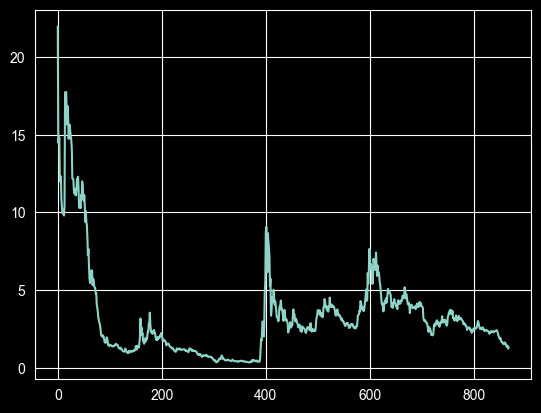

In [21]:
small_cap_data['close'].plot()

### download historical fundametal data

In [26]:
metrics = xfl.metrics(
    ['AAPL'],
    period_type = 'annual',
    fields = None,
    period = 'max'
)

In [16]:
metrics.to_excel('sample_fundamental_data.xlsx')

In [27]:
metrics.columns

Index(['entity_id', 'ticker', 'entity_name', 'period_end', 'period_type',
       'fiscal_year', 'fiscal_period', 'source', 'basis', 'shares_as_of',
       ...
       'fcf_growth', 'total_assets_growth', 'total_debt_growth',
       'capex_growth', 'market_cap_performance', 'realized_volatility_21d',
       'realized_volatility_63d', 'realized_volatility_252d', 'missing_inputs',
       'ttm_includes_derived_q4'],
      dtype='str', length=113)

<Axes: >

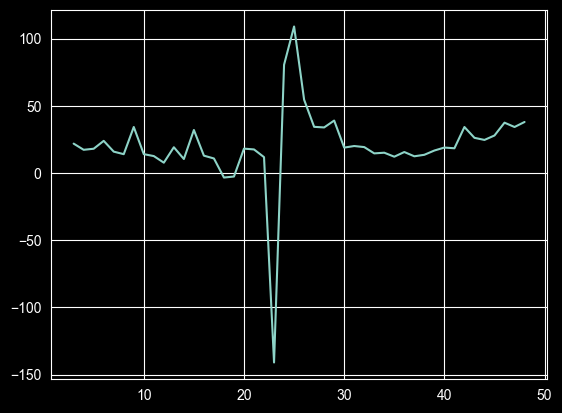

In [28]:
metrics['pe_ratio'].plot()

<Axes: >

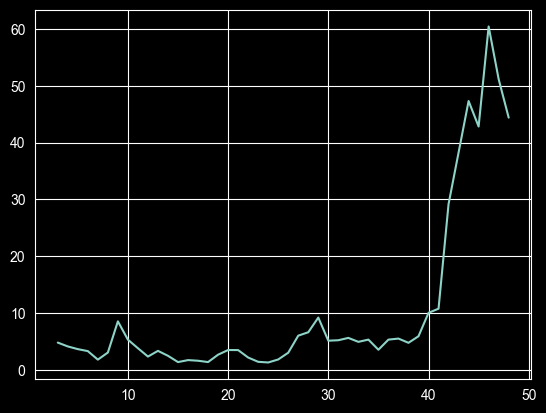

In [29]:
metrics['pb_ratio'].plot()

In [37]:
metrics

,entity_id,ticker,entity_name,period_end,period_type,fiscal_year,fiscal_period,source,basis,shares_as_of,...,fcf_growth,total_assets_growth,total_debt_growth,capex_growth,market_cap_performance,realized_volatility_21d,realized_volatility_63d,realized_volatility_252d,missing_inputs,ttm_includes_derived_q4
0,1,AAPL,APPLE INC,1978-09-30,annual,1978,FY,archive,annual,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'market_cap': ['market_cap:no_equity_class_tr...,False
1,1,AAPL,APPLE INC,1979-09-30,annual,1979,FY,archive,annual,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'market_cap': ['market_cap:no_equity_class_tr...,False
2,1,AAPL,APPLE INC,1980-09-30,annual,1980,FY,archive,annual,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,{'market_cap': ['market_cap:no_equity_class_tr...,False
3,1,AAPL,APPLE INC,1981-09-30,annual,1981,FY,archive,annual,1981-09-25,...,NaN,2.899587,0.355247,4.028495,NaN,0.630918,0.584574,NaN,"{'enterprise_value': ['cash_and_equivalents'],...",False
4,1,AAPL,APPLE INC,1982-09-30,annual,1982,FY,archive,annual,1982-09-24,...,NaN,0.403978,-0.454840,0.079131,0.243920,0.411929,0.517057,0.493071,"{'enterprise_value': ['cash_and_equivalents'],...",False
5,1,AAPL,APPLE INC,1983-09-30,annual,1983,FY,archive,annual,1983-09-30,...,NaN,0.555615,-0.823386,0.989649,0.299434,1.243272,0.866231,0.646211,"{'enterprise_value': ['cash_and_equivalents'],...",False
6,1,AAPL,APPLE INC,1984-09-30,annual,1984,FY,archive,annual,1984-09-28,...,NaN,0.417204,-1.000000,-0.247826,0.111025,0.323925,0.486044,0.549888,"{'enterprise_value': ['cash_and_equivalents'],...",False
7,1,AAPL,APPLE INC,1985-09-30,annual,1985,FY,archive,annual,1985-09-26,...,NaN,0.186858,NaN,0.364770,-0.359517,0.405186,0.335215,0.458785,"{'enterprise_value': ['cash_and_equivalents'],...",False
8,1,AAPL,APPLE INC,1986-09-30,annual,1986,FY,archive,annual,1986-09-26,...,NaN,0.239219,NaN,0.232410,1.153739,0.546387,0.493140,0.405476,"{'enterprise_value': ['cash_and_equivalents'],...",False
9,1,AAPL,APPLE INC,1987-09-30,annual,1987,FY,archive,annual,1987-09-25,...,NaN,0.273938,NaN,0.292635,2.395540,0.460569,0.433504,0.768369,"{'enterprise_value': ['cash_and_equivalents'],...",False


In [43]:
metrics.set_index(
    [
        'period_end',
        'fiscal_year',
        'ticker',
        'entity_id',
        'entity_name',
        'period_type',
        'fiscal_period',
        'source',
        'basis'
    ]
).stack().reset_index()

,period_end,fiscal_year,ticker,entity_id,entity_name,period_type,fiscal_period,source,basis,level_9,0
0,1978-09-30,1978,AAPL,1,APPLE INC,annual,FY,archive,annual,shares_as_of,NaN
1,1978-09-30,1978,AAPL,1,APPLE INC,annual,FY,archive,annual,shares_source,NaN
2,1978-09-30,1978,AAPL,1,APPLE INC,annual,FY,archive,annual,market_cap,NaN
3,1978-09-30,1978,AAPL,1,APPLE INC,annual,FY,archive,annual,enterprise_value,NaN
4,1978-09-30,1978,AAPL,1,APPLE INC,annual,FY,archive,annual,pe_ratio,NaN
...,...,...,...,...,...,...,...,...,...,...,...
5091,2026-09-26,2026,AAPL,1,APPLE INC,annual,FY,filing,annual,realized_volatility_21d,0.216451
5092,2026-09-26,2026,AAPL,1,APPLE INC,annual,FY,filing,annual,realized_volatility_63d,0.283804
5093,2026-09-26,2026,AAPL,1,APPLE INC,annual,FY,filing,annual,realized_volatility_252d,0.245779
5094,2026-09-26,2026,AAPL,1,APPLE INC,annual,FY,filing,annual,missing_inputs,"{'ev_ebitda': ['ebitda'], 'ev_ebit': ['ebit'],..."
